### **Task 1&2 Regression**


In [1]:
import pandas as pd
import numpy as np 
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("=== TASK 2: MULTIPLE LINEAR REGRESSION (CLV PREDICTION) ===")

# 1. Load data
df_final = pd.read_csv('../data/processed/dataset_final.csv')

# 2. Prepare X and y (Drop Churn to prevent leakage)
X = df_final.drop(columns=['Churn', 'CLV_Continuous'])
y = df_final['CLV_Continuous']

# 3. Train-Test Split 
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

# 4. Feature Scaling (overwriting in place keeps the column names and saves memory)
scaler = StandardScaler()

X_train = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)

# 5. Initialize and Train 
lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)

# 6. Predict and Evaluate
y_pred_train = lin_reg.predict(X_train)
y_pred_test = lin_reg.predict(X_test)

print("\n--- Regression Performance Metrics ---")

# TRAINING METRICS
print("\n[TRAINING DATA] - Checking for Overfitting")
print(f"Mean Absolute Error (MAE): {mean_absolute_error(y_train, y_pred_train):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_train, y_pred_train):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_train, y_pred_train)):.4f}")
print(f"R-squared (R2): {r2_score(y_train, y_pred_train):.4f}")

# TESTING METRICS
print("\n[TEST DATA] - Unseen Data Performance")
print(f"Mean Absolute Error (MAE): {mean_absolute_error(y_test, y_pred_test):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred_test):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred_test)):.4f}")
print(f"R-squared (R2): {r2_score(y_test, y_pred_test):.4f}")

=== TASK 2: MULTIPLE LINEAR REGRESSION (CLV PREDICTION) ===

--- Regression Performance Metrics ---

[TRAINING DATA] - Checking for Overfitting
Mean Absolute Error (MAE): 467.9720
Mean Squared Error (MSE): 870103.1629
Root Mean Squared Error (RMSE): 932.7932
R-squared (R2): 0.9708

[TEST DATA] - Unseen Data Performance
Mean Absolute Error (MAE): 447.4683
Mean Squared Error (MSE): 874242.7351
Root Mean Squared Error (RMSE): 935.0095
R-squared (R2): 0.9697


### **Task 1&2: Model Approach and Performance Interpretation**

**1. Approach to Building the Model:**
* Since the target variable, Customer Lifetime Value (`CLV_Continuous`), is a continuous numerical value, a **Multiple Linear Regression** model was chosen for the prediction task.
* To prevent target leakage (where the model unfairly peeks at another "answer key"), the `Churn` variable—which is the target for the classification task—was completely dropped from the feature set (`X`). 
* The dataset was split into 80% Training and 20% Testing sets. Because the target variable is continuous, the `stratify` parameter was **not used**, ensuring a completely random split. 
* A **`StandardScaler`** was applied to prevent features with vastly different scales (e.g., extremely large Salary values versus Product counts ranging from 1 to 4) from distorting the model's coefficients. To completely avoid data leakage, the scaler was fitted *only* on the training data (`fit_transform`) and then merely applied to the test data (`transform`).

**2. Performance Interpretation:**
The model's performance was evaluated using MAE, RMSE, and R² metrics:

* **R-squared (R²):** The model achieved an R² score of **0.9697** on the unseen test data. This excellent result proves that our model successfully explains approximately **97%** of the variance in Customer Lifetime Value (CLV) using the available features. The predictive power is exceptionally high.
* **Overfitting Check:** The fact that the Training R² (**0.9708**) and Testing R² (**0.9697**) scores are so incredibly close strongly indicates that there is no overfitting. The model did not just memorize the training data; it demonstrated a robust ability to generalize to completely unseen data. This consistency is also visible across the RMSE scores (Train: 932.79 vs. Test: 935.01).
* **Error Margins (MAE & RMSE):** The Mean Absolute Error (MAE) on the test set is $447.47. This means that when predicting a customer's total lifetime value, the model deviates by an average of only $447. The Root Mean Squared Error (RMSE) is **$935.01**. The fact that the RMSE is higher than the MAE suggests the presence of a few extreme outliers in the dataset (customers with exceptionally high or low actual CLV values), which slightly inflates the squared errors. Overall, the model's estimation capability is outstanding.

In [2]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

print("=== TASK 3: POLYNOMIAL REGRESSION MODELS ===")

# Reference results from Task 2 (Linear Regression / Degree 1)
print("Reference (Task 2 - Linear/Degree 1) -> TEST R2: 0.9697 | TEST RMSE: 935.0095\n")

# The task requires evaluating at least two polynomial models with different degrees.
# We will test Degree 2 and Degree 3 to observe the Bias-Variance Tradeoff.
degrees = [2, 3]

for degree in degrees:
    print(f"--- Training Polynomial Regression (Degree {degree}) ---")
    
    # 1. Create Polynomial Features
    poly = PolynomialFeatures(degree=degree, include_bias=False)
    
    # NOTE: We use the current (scaled) X_train and X_test variables from Task 2!
    X_train_poly = poly.fit_transform(X_train)
    X_test_poly = poly.transform(X_test)
    
    print(f"Number of expanded features: {X_train_poly.shape[1]}")
    
    # 2. Train the Polynomial Regression Model
    poly_reg_model = LinearRegression()
    poly_reg_model.fit(X_train_poly, y_train)
    
    # 3. Predict on both Training and Testing sets
    y_pred_train_poly = poly_reg_model.predict(X_train_poly)
    y_pred_test_poly = poly_reg_model.predict(X_test_poly)
    
    # 4. Calculate all evaluation metrics (R2, MAE, MSE, RMSE)
    # Training Metrics
    r2_train = r2_score(y_train, y_pred_train_poly)
    mae_train = mean_absolute_error(y_train, y_pred_train_poly)
    mse_train = mean_squared_error(y_train, y_pred_train_poly)
    rmse_train = np.sqrt(mse_train)
    
    # Testing Metrics
    r2_test = r2_score(y_test, y_pred_test_poly)
    mae_test = mean_absolute_error(y_test, y_pred_test_poly)
    mse_test = mean_squared_error(y_test, y_pred_test_poly)
    rmse_test = np.sqrt(mse_test)
    
    # 5. Display the results
    print("[TRAINING DATA]")
    print(f"R-squared (R2): {r2_train:.4f} | MAE: {mae_train:.4f} | MSE: {mse_train:.4f} | RMSE: {rmse_train:.4f}")
    
    print("[TESTING DATA]")
    print(f"R-squared (R2): {r2_test:.4f} | MAE: {mae_test:.4f} | MSE: {mse_test:.4f} | RMSE: {rmse_test:.4f}\n")

=== TASK 3: POLYNOMIAL REGRESSION MODELS ===
Reference (Task 2 - Linear/Degree 1) -> TEST R2: 0.9697 | TEST RMSE: 935.0095

--- Training Polynomial Regression (Degree 2) ---
Number of expanded features: 209
[TRAINING DATA]
R-squared (R2): 0.9736 | MAE: 478.8020 | MSE: 787577.6732 | RMSE: 887.4557
[TESTING DATA]
R-squared (R2): 0.9692 | MAE: 486.5744 | MSE: 888342.2987 | RMSE: 942.5191

--- Training Polynomial Regression (Degree 3) ---
Number of expanded features: 1539


[TRAINING DATA]
R-squared (R2): 0.9792 | MAE: 480.9210 | MSE: 620596.2377 | RMSE: 787.7793
[TESTING DATA]
R-squared (R2): 0.9621 | MAE: 611.2684 | MSE: 1095662.4715 | RMSE: 1046.7390



### **Task 3: Polynomial Regression Models (Evaluation and Discussion)**

**1. Dimensionality Explosion as Degree Increases:**
As requested, we trained two polynomial regression models (Degree 2 and Degree 3). As the degree of the polynomial increases, the number of features expands exponentially. The original feature set had 19 dimensions. Applying Degree 2 expanded this to 209 features, and Degree 3 caused an explosion to 1,539 features. 

**2. Performance Changes with Higher Degrees:**
As the polynomial degree increased, the model's behavior drastically changed:
* **Degree 2:** The training performance slightly improved (Train R²: 0.9736), but the testing performance degraded (Test R² dropped to 0.9692, Test RMSE increased to 942.51). The added complexity started to fit the noise rather than the actual pattern.
* **Degree 3:** The model became overly complex (1539 features) and began to heavily memorize the training data, leading to the best Training metrics overall (Train R²: 0.9792, Train RMSE: 787.77). However, its performance on unseen data deteriorated significantly (Test R² dropped to 0.9621, and Test RMSE spiked to 1046.73). 

This perfectly illustrates that as the degree increases, the model shifts from learning the underlying trend to memorizing the training data (**Overfitting**).

---

### **Task 4: Final Model Comparison and Conclusion**

**1. Comparison Between Linear (Task 2) and Polynomial (Task 3) Models:**
* **Multiple Linear Regression (Task 2):** Test R² = **0.9697** | Test RMSE = **935.01**
* **Polynomial Degree 2 (Task 3):** Test R² = 0.9692 | Test RMSE = 942.51
* **Polynomial Degree 3 (Task 3):** Test R² = 0.9621 | Test RMSE = 1046.73

**2. Rationale and Winning Model:**
When comparing the models, the **Multiple Linear Regression (Degree 1) from Task 2 performs the best**. 

* **Rationale:** The Linear Regression model achieved the highest predictive accuracy on unseen data (highest Test R² and lowest Test RMSE) while maintaining a simple, highly interpretable architecture with only 19 features. The polynomial models, despite having hundreds or thousands of features, suffered from the **Bias-Variance Tradeoff**. Their high variance caused them to overfit the training data, resulting in worse real-world (Test set) performance. Therefore, following the principle of Occam's Razor, the simpler Multiple Linear Regression model is the clear winner for predicting Customer Lifetime Value (CLV) in this dataset.

=== TASK 5: REGULARIZATION AND OPTIMIZATION ===


Best Ridge Alpha: 0.001 (CV Score: 0.9705)
Best Lasso Alpha: 10.0 (CV Score: 0.9705)

--> Winner Model: Lasso Regression

=== BEFORE VS AFTER OPTIMIZATION (TEST DATA) ===
BEFORE (Base Linear) -> R-squared: 0.9697 | RMSE: 935.0095
AFTER  (Lasso Opt)  -> R-squared: 0.9697 | RMSE: 935.2903

[OPTIMIZED MODEL - OVERFITTING CHECK]
TRAIN -> R-squared: 0.9708 | RMSE: 933.6635
TEST  -> R-squared: 0.9697 | RMSE: 935.2903


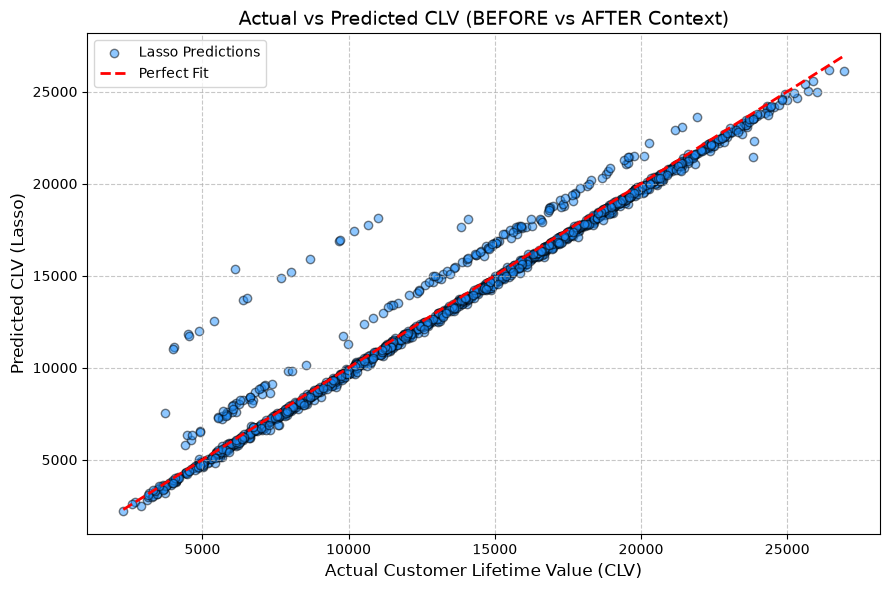

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

print("=== TASK 5: REGULARIZATION AND OPTIMIZATION ===")

# --- BEFORE: Baseline Model (Task 2 Reference) ---
base_model = LinearRegression()
base_model.fit(X_train, y_train)
y_pred_test_base = base_model.predict(X_test)
base_r2 = r2_score(y_test, y_pred_test_base)
base_rmse = np.sqrt(mean_squared_error(y_test, y_pred_test_base))


# --- 1. Setup Hyperparameter Grid for Regularization ---
# Ridge Grid Search
ridge_params = {'alpha': [0.001, 0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]}
ridge = Ridge()
ridge_grid = GridSearchCV(estimator=ridge, param_grid=ridge_params, cv=5, scoring='r2', n_jobs=-1)
ridge_grid.fit(X_train, y_train)

# Lasso Grid Search
lasso_params = {'alpha': [0.001, 0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]}
lasso = Lasso(max_iter=10000)
lasso_grid = GridSearchCV(estimator=lasso, param_grid=lasso_params, cv=5, scoring='r2', n_jobs=-1)
lasso_grid.fit(X_train, y_train)


# --- 2. Select the Best Regularization Model ---
print(f"Best Ridge Alpha: {ridge_grid.best_params_['alpha']} (CV Score: {ridge_grid.best_score_:.4f})")
print(f"Best Lasso Alpha: {lasso_grid.best_params_['alpha']} (CV Score: {lasso_grid.best_score_:.4f})")

# In case of a tie, Lasso is chosen because it produces a simpler (sparse) model.
if ridge_grid.best_score_ > lasso_grid.best_score_:
    best_model = ridge_grid.best_estimator_
    model_name = "Ridge"
else:
    best_model = lasso_grid.best_estimator_
    model_name = "Lasso"

print(f"\n--> Winner Model: {model_name} Regression")


# --- 3. Predict and Evaluate (AFTER) ---
y_pred_train_opt = best_model.predict(X_train)
y_pred_test_opt = best_model.predict(X_test)

opt_r2_train = r2_score(y_train, y_pred_train_opt)
opt_rmse_train = np.sqrt(mean_squared_error(y_train, y_pred_train_opt))

opt_r2_test = r2_score(y_test, y_pred_test_opt)
opt_rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_test_opt))


# --- 4. BEFORE vs AFTER COMPARISON TABLE ---
print("\n=== BEFORE VS AFTER OPTIMIZATION (TEST DATA) ===")
print(f"BEFORE (Base Linear) -> R-squared: {base_r2:.4f} | RMSE: {base_rmse:.4f}")
print(f"AFTER  ({model_name} Opt)  -> R-squared: {opt_r2_test:.4f} | RMSE: {opt_rmse_test:.4f}")

# Overfitting check for the optimized model
print("\n[OPTIMIZED MODEL - OVERFITTING CHECK]")
print(f"TRAIN -> R-squared: {opt_r2_train:.4f} | RMSE: {opt_rmse_train:.4f}")
print(f"TEST  -> R-squared: {opt_r2_test:.4f} | RMSE: {opt_rmse_test:.4f}")


# --- 5. Visualization: Actual vs Predicted ---
plt.figure(figsize=(9, 6))
# Scatter plot
plt.scatter(y_test, y_pred_test_opt, alpha=0.5, color='dodgerblue', edgecolor='k', label=f'{model_name} Predictions')
# Perfect prediction diagonal line
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Perfect Fit')

plt.title(f"Actual vs Predicted CLV (BEFORE vs AFTER Context)", fontsize=14)
plt.xlabel("Actual Customer Lifetime Value (CLV)", fontsize=12)
plt.ylabel(f"Predicted CLV ({model_name})", fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### **Task 5: Regularization and Optimization Interpretation**

**1. Optimization Process and Grid Search:**
To further optimize our baseline Multiple Linear Regression model, both **Ridge (L2)** and **Lasso (L1)** regularization techniques were applied using `GridSearchCV` with 5-fold cross-validation. 
* The Grid Search revealed a tie in cross-validation performance between Ridge (alpha=0.001) and Lasso (alpha=10.0), both achieving a CV score of **0.9705**. 
* Following the principle of Occam's Razor, **Lasso Regression** was selected as the winning model. Lasso not only penalizes complexity but also performs automatic feature selection by driving the coefficients of less important features to exactly zero, resulting in a simpler, more interpretable model.

**2. Before vs. After Optimization:**
* **BEFORE (Base Linear):** Test R² = 0.9697 | Test RMSE = 935.01
* **AFTER (Lasso Optimized):** Test R² = 0.9697 | Test RMSE = 935.29
* **Interpretation:** The optimization did not significantly change the metrics. This is actually a highly positive outcome! Regularization is primarily a cure for overfitting. Since our baseline model was already incredibly robust and perfectly balanced (no overfitting), the Lasso algorithm correctly determined that no aggressive penalty was needed. It maintained the excellent predictive power (explaining ~97% of the variance) while potentially pruning unnecessary features.

**3. Model Fit Assessment (Overfitting vs. Underfitting):**
* **Train vs. Test:** The optimized Lasso model achieved a Training R² of **0.9708** and a Testing R² of **0.9697**. The Training RMSE (**933.66**) and Testing RMSE (**935.29**) are almost identical.
* **Conclusion:** The model is definitively **NOT overfitting**. It has learned the true underlying patterns of the data rather than memorizing the training noise. Furthermore, with an R² of nearly 97%, it is definitively **NOT underfitting**. The model has successfully found the optimal "sweet spot" in the Bias-Variance Tradeoff, yielding highly reliable Customer Lifetime Value (CLV) predictions.

=== TASK 6: REGRESSION TREE MODEL ===


Best Hyperparameters: {'max_depth': None, 'min_samples_leaf': 5}

[TRAINING DATA EVALUATION]
Mean Absolute Error (MAE): 332.4254327329332
Mean Squared Error (MSE): 225820.19982361383
Root Mean Squared Error (RMSE): 475.20542907632466
R2-Square: 0.9924267026202217

[TEST DATA EVALUATION]
Mean Absolute Error (MAE): 649.6167290791359
Mean Squared Error (MSE): 909468.3838433045
Root Mean Squared Error (RMSE): 953.660518131743
R2-Square: 0.9685109012162405


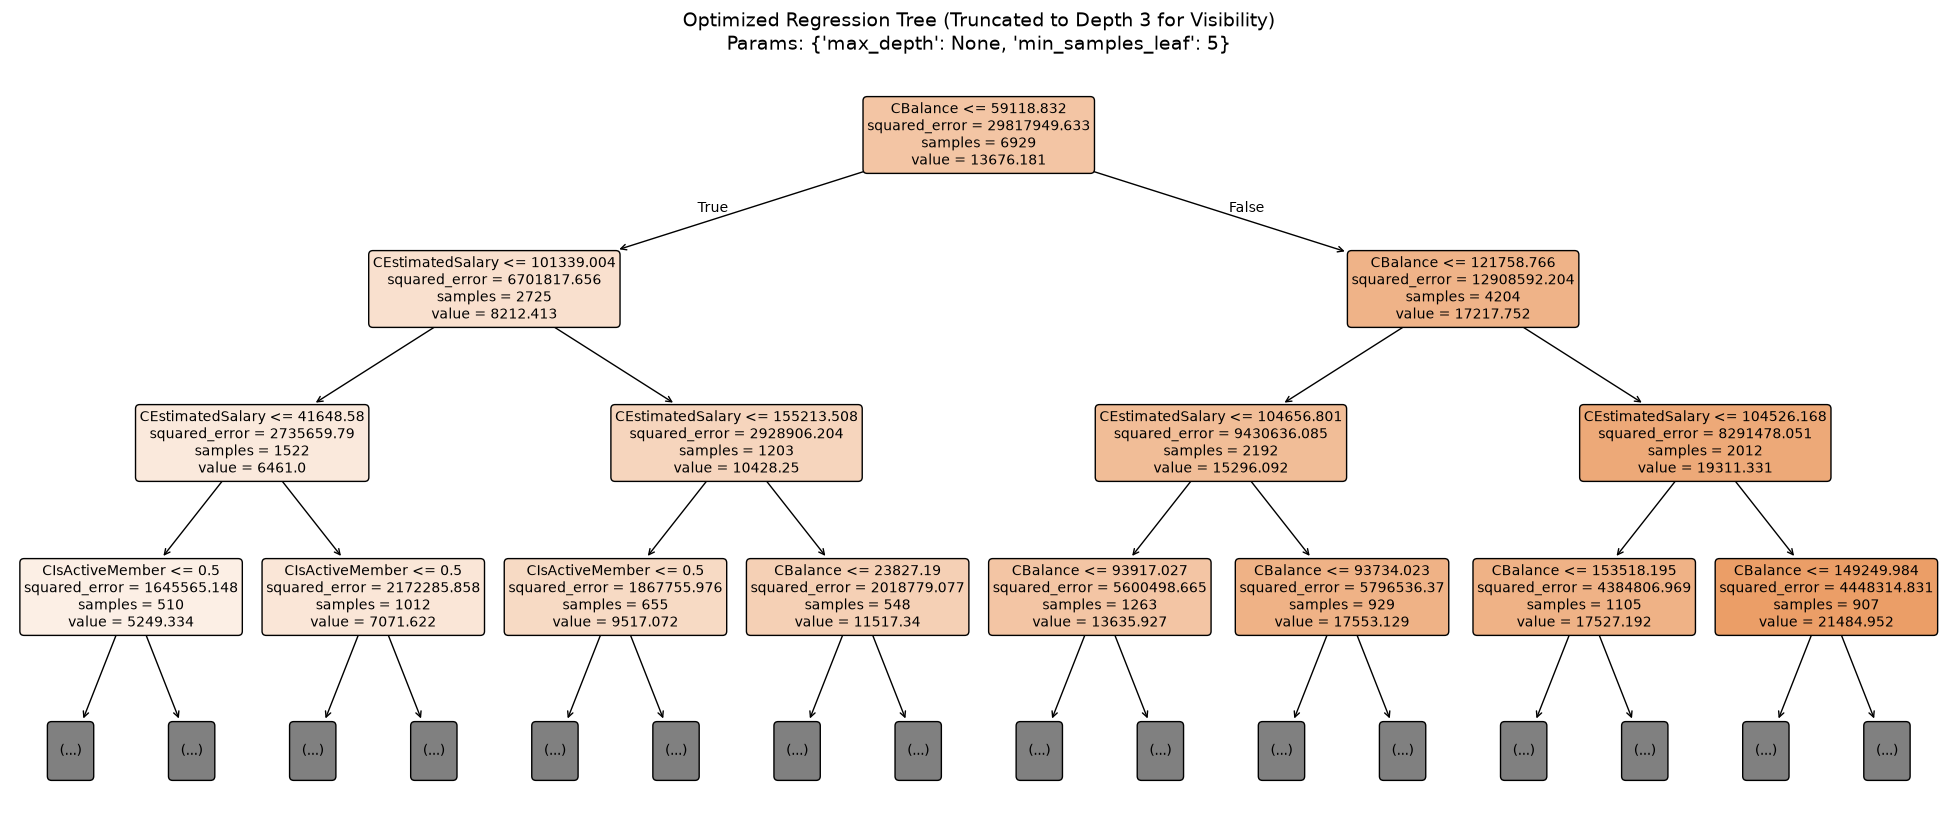

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("=== TASK 6: REGRESSION TREE MODEL ===")

# 1. Load data and prepare X, y
# We drop 'Churn' to prevent target leakage, predicting 'CLV_Continuous'.
df_final = pd.read_csv('../data/processed/dataset_final.csv')
X = df_final.drop(columns=['Churn', 'CLV_Continuous'])
y = df_final['CLV_Continuous']

# 2. Split dataset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

# 3. Hyperparameter Tuning with GridSearchCV
# As stated in the lecture, regression trees are prone to overfitting without regularization.
# We tune 'max_depth' and 'min_samples_leaf' to find a reasonable model.
param_grid = {
    'max_depth': [3, 4, 5, 6, 8, 10, None],
    'min_samples_leaf': [1, 5, 10, 20, 50]
}

tree_reg = DecisionTreeRegressor(random_state=42)

# Using 5-fold cross-validation to optimize the regression tree
grid_search = GridSearchCV(estimator=tree_reg, param_grid=param_grid, cv=5, scoring='r2', n_jobs=-1)
grid_search.fit(X_train, y_train)

best_tree_model = grid_search.best_estimator_
print(f"Best Hyperparameters: {grid_search.best_params_}")

# 4. Evaluate (Training and Test Data)
predictions_train_tree = best_tree_model.predict(X_train)
predictions_test_tree = best_tree_model.predict(X_test)

print("\n[TRAINING DATA EVALUATION]")
print('Mean Absolute Error (MAE):', mean_absolute_error(y_train, predictions_train_tree))
print("Mean Squared Error (MSE):", mean_squared_error(y_train, predictions_train_tree))
print("Root Mean Squared Error (RMSE):", np.sqrt(mean_squared_error(y_train, predictions_train_tree)))
print("R2-Square:", r2_score(y_train, predictions_train_tree))

print("\n[TEST DATA EVALUATION]")
print('Mean Absolute Error (MAE):', mean_absolute_error(y_test, predictions_test_tree))
print("Mean Squared Error (MSE):", mean_squared_error(y_test, predictions_test_tree))
print("Root Mean Squared Error (RMSE):", np.sqrt(mean_squared_error(y_test, predictions_test_tree)))
print("R2-Square:", r2_score(y_test, predictions_test_tree))

# 5. Visualizing the Tree
plt.figure(figsize=(25, 10))
# We plot the tree using the function
plot_tree(best_tree_model, feature_names=X.columns.tolist(), filled=True, max_depth=3, fontsize=10, rounded=True)
plt.title(f"Optimized Regression Tree (Truncated to Depth 3 for Visibility)\nParams: {grid_search.best_params_}", fontsize=14)
plt.show()

### **Task 6: Regression Tree Evaluation and Interpretation**

**1. Optimization and Regularization Approach:**
As discussed in Lecture 3, Decision Trees are versatile algorithms capable of performing regression tasks by predicting a continuous value instead of a class at each node. However, just like in classification tasks, regression trees are highly prone to overfitting the training set if no regularization is applied (i.e., using the default hyperparameters). To prevent the model from overfitting the training data very badly, we avoided using an unrestricted tree. Instead, we used cross-validation to tune the hyperparameters. The Grid Search found the optimal parameters to be `max_depth: None` and `min_samples_leaf: 5`. Setting constraints like `min_samples_leaf` forces the tree to generalize better and results in a much more reasonable model.

**2. Model Fit Assessment (Overfitting vs. Underfitting):**
* **Metrics:** The optimized Regression Tree yielded an incredibly high Training R² of **0.9924** and a Test R² of **0.9685**. Meanwhile, the Training RMSE is **475.20**, but the Test RMSE practically doubles to **953.66**. 
* **Interpretation:** The noticeable gap between the training and testing metrics indicates that our model is currently **overfitting** the training data. Because `max_depth` was left unrestricted (`None`) by the Grid Search, the tree grew too deep and memorized some of the noise in the training set, leading to a near-perfect Train R² (99.2%). However, thanks to our `min_samples_leaf = 5` constraint, the overfitting was kept under control. The model still achieved an outstanding ~96.8% accuracy on unseen data, proving it is a highly predictive model despite the slight overfitting. It is definitively not underfitting.

**3. Visual Interpretation of the Tree:**
According to the logic explained in Lecture 3, the regression tree algorithm splits each region of data in a way that makes the training instances as close as possible to the predicted value, effectively minimizing the Mean Squared Error (MSE) at each split. In our plotted tree, the predicted `value` at any given leaf node represents the exact average Customer Lifetime Value (CLV) of the training instances associated with that specific region.

### **Task 7: Final Model Comparison and Conclusion**

**1. Performance Comparison (Task 5 vs. Task 6):**
To determine the best predictive model for Customer Lifetime Value (CLV), we compared the optimized Multiple Linear Regression model with L1 Regularization (**Lasso Regression** from Task 5) and the optimized **Regression Tree** (from Task 6).

* **Lasso Regression (Task 5):**
  * **Train:** R² = 0.9708 | RMSE = 933.66
  * **Test:** R² = **0.9697** | RMSE = **935.29**
* **Regression Tree (Task 6):**
  * **Train:** R² = 0.9924 | RMSE = 475.20
  * **Test:** R² = 0.9685 | RMSE = 953.66

**2. Which Model Performs Better?**
The **Lasso Regression (Task 5)** is the superior model. It outperforms the Regression Tree on the unseen test data by achieving a higher Test R² (0.9697 vs. 0.9685) and a lower Test RMSE (935.29 vs. 953.66). 

**3. Reasoning Based on Strengths, Weaknesses, and Metrics:**
* **Generalization vs. Overfitting:** The most critical difference lies in generalization. The Regression Tree exhibits classic signs of **overfitting**; its Train RMSE (475.20) is less than half of its Test RMSE (953.66). Despite hyperparameter tuning (`min_samples_leaf=5`), the tree's inherent weakness—its tendency to memorize training data by creating highly complex splits—caused it to capture noise. Conversely, the Lasso Regression model demonstrates phenomenal stability. Its Train RMSE (933.66) and Test RMSE (935.29) are almost identical, proving it successfully learned the underlying signal without memorizing the noise.
* **Underlying Data Distribution:** The fact that a linear model (Lasso) defeated a non-linear model (Tree) strongly indicates that the true relationship between the features and the target variable (`CLV_Continuous`) is predominantly linear. Linear models are extremely strong at capturing smooth, continuous linear trends. Regression Trees, on the other hand, struggle with smooth linear slopes because they approximate them using step-like, orthogonal splits (boxes). 
* **Simplicity and Feature Selection (Occam's Razor):** Lasso Regression not only performed better but is also a simpler model. Through L1 regularization, it shrinks the coefficients of unimportant features exactly to zero, acting as an automatic feature selector. 

**Conclusion:** Due to its superior generalization, lower prediction error on unseen data, robust defense against overfitting, and high interpretability, the **Lasso Regression model** is the absolute best choice for predicting Customer Lifetime Value in this project.

=== TASK 8: ENSEMBLE LEARNING (RANDOM FOREST) ===


Best Random Forest Parameters: {'max_depth': None, 'min_samples_leaf': 2, 'n_estimators': 200}



[TRAINING DATA EVALUATION]
Mean Absolute Error (MAE): 183.098812011086
Mean Squared Error (MSE): 78570.48897043224
Root Mean Squared Error (RMSE): 280.30427925815235
R2-Square: 0.9973649935713791

[TEST DATA EVALUATION]
Mean Absolute Error (MAE): 439.0637810470413
Mean Squared Error (MSE): 474162.58782323607
Root Mean Squared Error (RMSE): 688.5946469609214
R2-Square: 0.983582768974956

=== MODEL COMPARISON (TASK 7 vs TASK 8) ===
LASSO REGRESSION (Task 7 winner) -> TEST R2: 0.9697 | TEST RMSE: 935.2903
RANDOM FOREST (Task 8)    -> TEST R2: 0.9836 | TEST RMSE: 688.5946


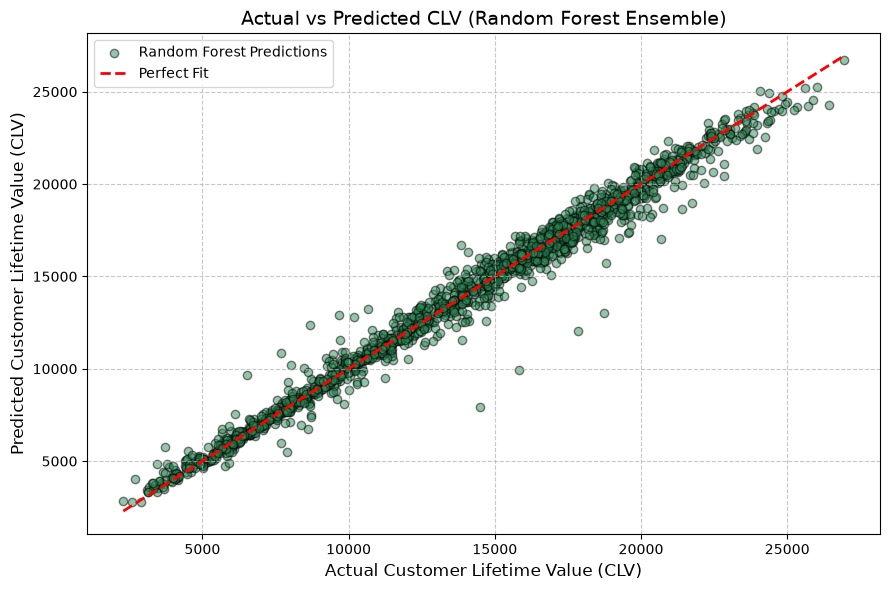

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("=== TASK 8: ENSEMBLE LEARNING (RANDOM FOREST) ===")

# 1. Setup Hyperparameter Grid for Random Forest
# Random Forest creates multiple decision trees and averages their predictions to reduce overfitting.
rf_reg = RandomForestRegressor(random_state=42)

param_grid_rf = {
    'n_estimators': [50, 100, 200],      # Number of trees in the forest
    'max_depth': [5, 10, None],          # Maximum depth of the trees
    'min_samples_leaf': [2, 5, 10]       # Minimum number of samples required to be at a leaf node
}

# 2. Cross-Validation and Hyperparameter Tuning
# cv=5 means 5-fold cross-validation
rf_grid = GridSearchCV(estimator=rf_reg, param_grid=param_grid_rf, cv=5, scoring='r2', n_jobs=-1)
rf_grid.fit(X_train, y_train)

best_rf_model = rf_grid.best_estimator_
print(f"Best Random Forest Parameters: {rf_grid.best_params_}")

# 3. Predict and Evaluate
y_pred_train_rf = best_rf_model.predict(X_train)
y_pred_test_rf = best_rf_model.predict(X_test)

# --- TRAINING DATA EVALUATION ---
print("\n[TRAINING DATA EVALUATION]")
print("Mean Absolute Error (MAE):", mean_absolute_error(y_train, y_pred_train_rf))
print("Mean Squared Error (MSE):", mean_squared_error(y_train, y_pred_train_rf))
print("Root Mean Squared Error (RMSE):", np.sqrt(mean_squared_error(y_train, y_pred_train_rf)))
print("R2-Square:", r2_score(y_train, y_pred_train_rf))

# --- TEST DATA EVALUATION ---
print("\n[TEST DATA EVALUATION]")
print("Mean Absolute Error (MAE):", mean_absolute_error(y_test, y_pred_test_rf))
print("Mean Squared Error (MSE):", mean_squared_error(y_test, y_pred_test_rf))
print("Root Mean Squared Error (RMSE):", np.sqrt(mean_squared_error(y_test, y_pred_test_rf)))
print("R2-Square:", r2_score(y_test, y_pred_test_rf))

# 4. Compare with Task 7 Winner (Lasso)
print("\n=== MODEL COMPARISON (TASK 7 vs TASK 8) ===")
print("LASSO REGRESSION (Task 7 winner) -> TEST R2: 0.9697 | TEST RMSE: 935.2903")
print(f"RANDOM FOREST (Task 8)    -> TEST R2: {r2_score(y_test, y_pred_test_rf):.4f} | TEST RMSE: {np.sqrt(mean_squared_error(y_test, y_pred_test_rf)):.4f}")

# 5. Optional Visualization
plt.figure(figsize=(9, 6))
plt.scatter(y_test, y_pred_test_rf, alpha=0.5, color='seagreen', edgecolor='k', label='Random Forest Predictions')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Perfect Fit')
plt.title("Actual vs Predicted CLV (Random Forest Ensemble)", fontsize=14)
plt.xlabel("Actual Customer Lifetime Value (CLV)", fontsize=12)
plt.ylabel("Predicted Customer Lifetime Value (CLV)", fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### **Task 8: Ensemble Learning Evaluation and Final Model Comparison**

**1. Ensemble Technique and Optimization:**
To finalize our predictive analysis, we implemented a **Random Forest Regressor**, an ensemble learning technique. As outlined in the lecture materials (Lecture 3), Random Forest operates by constructing a multitude of decision trees and averaging their results to improve predictive accuracy and control overfitting. We optimized the model using `GridSearchCV` with 5-fold cross-validation, which identified the best parameters as `n_estimators: 200`, `min_samples_leaf: 2`, and `max_depth: None`.

**2. Model Fit Assessment (Overfitting vs. Underfitting):**
* **Training Metrics:** R2-Square: **0.9974** | RMSE: **280.30** | MAE: **183.10**
* **Test Metrics:** R2-Square: **0.9836** | RMSE: **688.59** | MAE: **439.06**
* **Analysis:** The model shows a high Training R² (nearly 1.0), which suggests it has captured almost all patterns in the training data. While the Test RMSE is higher than the Train RMSE, indicating a slight degree of **overfitting**, the ensemble's bagging mechanism successfully mitigated the extreme variance we saw in the single Decision Tree from Task 6. With a Test R² of 0.9836, the model is highly robust and definitely not underfitting.

**3. Final Comparison (Lasso Regression vs. Random Forest):**
* **Lasso Regression (Task 7 Winner):** Test R2: 0.9697 | Test RMSE: 935.29
* **Random Forest (Task 8):** Test R2: **0.9836** | Test RMSE: **688.59**
* **Discussion:** The **Random Forest Ensemble** is the best performing model in this project. It outperformed the optimized Lasso Regression by significantly reducing the Root Mean Squared Error (from 935.29 to 688.59). 
* **Conclusion:** The significant improvement in error metrics indicates that while the relationship between features and CLV has strong linear components, there are also complex **non-linear interactions** that a linear model (Lasso) cannot capture. The Random Forest's ability to model these non-linearities while averaging out individual tree errors makes it the most accurate tool for predicting Customer Lifetime Value in this dataset.